# LightGBM vs XGBoost selected M4 vs baselines

This notebook compares the selected-feature M4 models and the three baseline forecasts on the same held-out 2018 operating-hours rows. LightGBM `M4 (B)` is the tuned selected-M4 result from `3-LightGBM/M1_M4_Comparison.ipynb`; XGBoost is `correlation_reduced_M4`, using M4 after excluding `floor`, `month`, and `is_weekend` based on `Feature Selection/feature_selection.ipynb`.

Metrics: MAE, RMSE, WAPE, CV(RMSE), and NMBE. Lower values are better for all metrics except that NMBE is interpreted as bias, so values closer to zero are preferable.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name != 'Qn_B':
    ROOT = next(p for p in [ROOT, *ROOT.parents] if p.name == 'Qn_B')
LGBM_METRICS = ROOT / '3-LightGBM' / 'outputs' / 'm1_m4_test_metrics.csv'
XGB_METRICS = ROOT / '4-XGBoost' / 'outputs' / 'final_models' / 'selected_m4_vs_lightgbm_baselines.csv'
OUT = ROOT / 'outputs' / 'model_metrics_comparison'
OUT.mkdir(parents=True, exist_ok=True)


In [2]:
lgbm = pd.read_csv(LGBM_METRICS)
lgbm = lgbm[(lgbm['model'].isin(['M4 (B)', 'B1 seasonal naive', 'B2 average profile', 'B3 calendar + AC lags'])) & (lgbm['hours'].eq('operating hours'))].copy()
lgbm['model'] = lgbm['model'].replace({'M4 (B)': 'LightGBM selected M4'})
lgbm = lgbm[['model', 'MAE', 'RMSE', 'CV(RMSE)%', 'NMBE%', 'WAPE%']]

xgb = pd.read_csv(XGB_METRICS)
xgb = xgb[(xgb['scope'].eq('operating hours')) & (xgb['model'].eq('XGBoost M4 selected'))].copy()
xgb = xgb.rename(columns={'scope': 'hours', 'model': 'model'})
xgb = xgb[['model', 'MAE', 'RMSE', 'CV(RMSE)%', 'NMBE%', 'WAPE%']]

comparison = pd.concat([lgbm, xgb], ignore_index=True)
order = ['LightGBM selected M4', 'XGBoost M4 selected', 'B1 seasonal naive', 'B2 average profile', 'B3 calendar + AC lags']
comparison['model'] = pd.Categorical(comparison['model'], categories=order, ordered=True)
comparison = comparison.sort_values('model').reset_index(drop=True)
display(comparison.round(3))
comparison.to_csv(OUT / 'operating_hours_metrics.csv', index=False)


,model,MAE,RMSE,CV(RMSE)%,NMBE%,WAPE%
0,LightGBM selected M4,1.700,2.780,20.340,-0.510,12.430
1,XGBoost M4 selected,1.782,2.803,20.498,-2.186,13.034
2,B1 seasonal naive,2.310,4.770,34.870,4.700,16.920
3,B2 average profile,2.660,3.850,28.130,-11.830,19.470
4,B3 calendar + AC lags,2.480,4.020,29.410,4.070,18.120


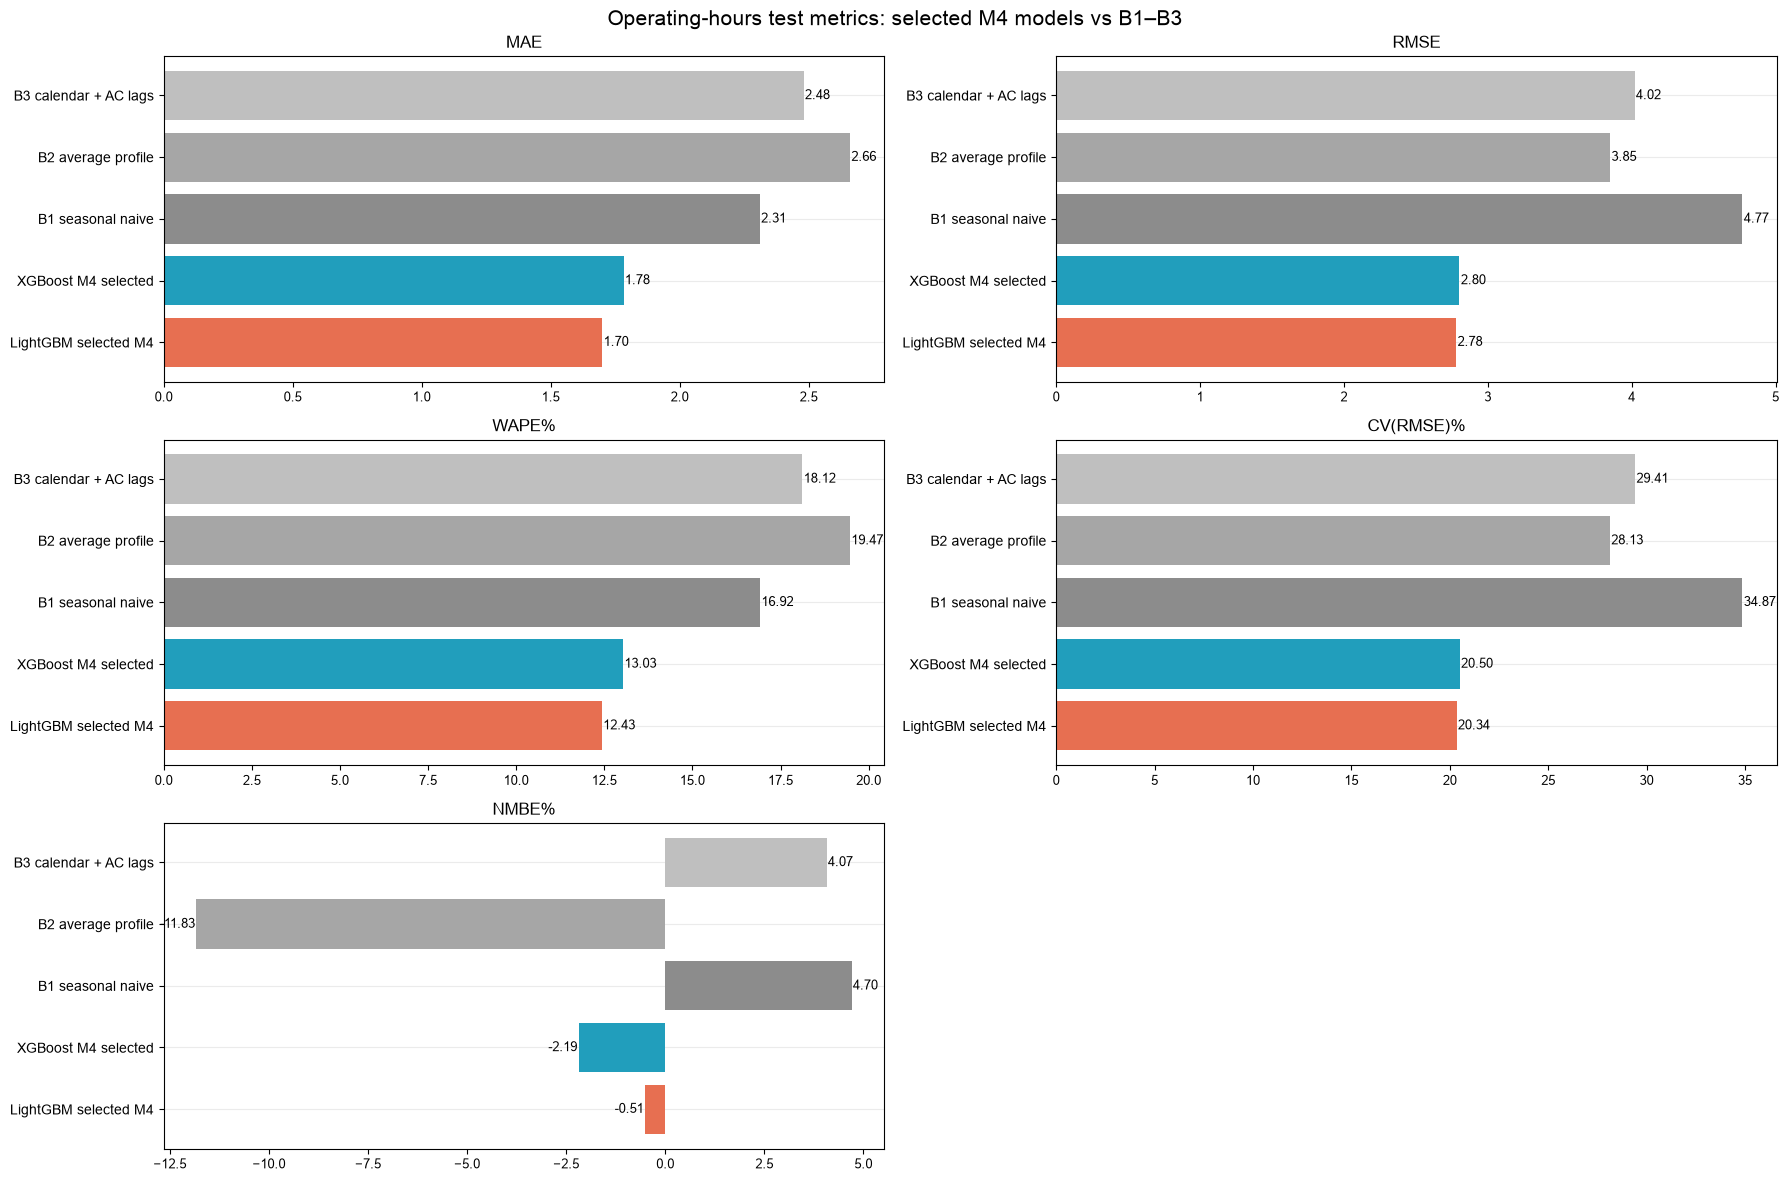

In [3]:
plt.rcParams['font.sans-serif'] = ['Arial']
metrics = ['MAE', 'RMSE', 'WAPE%', 'CV(RMSE)%', 'NMBE%']
fig, axes = plt.subplots(3, 2, figsize=(18, 12))
colors = ['#e76f51', '#219ebc', '#8C8C8C', '#A6A6A6', '#BFBFBF']
for ax, metric in zip(axes.flat, metrics):
    values = comparison[metric].astype(float)
    bars = ax.barh(comparison['model'].astype(str), values, color=colors)
    ax.bar_label(bars, fmt='%.2f', padding=1, fontsize=9)
    ax.set_title(metric)
    ax.tick_params(axis='x', labelsize=9)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
axes.flat[-1].axis('off')
fig.suptitle('Operating-hours test metrics: selected M4 models vs B1–B3', fontsize=15)
fig.tight_layout()
fig.savefig(OUT / 'operating_hours_metrics_comparison.png', dpi=180, bbox_inches='tight')
plt.show()


## Interpretation

The comparison is based on the LightGBM M4 (B) result and the XGBoost selected M4 result, both evaluated against B1, B2, and B3 on operating hours. The baseline and model rows come from the same held-out test period and use the project's scored-row protocol.


## LightGBM forecast versus actual by zone

Pooled metrics can hide weak zones. This section uses only the LightGBM `LGBM final` forecast and selects the best, typical, and worst zones using operating-hours WAPE on the held-out test period.


In [4]:
lgbm_pred = pd.read_parquet(ROOT / '3-LightGBM' / 'outputs' / 'test_predictions.parquet')
plot_df = lgbm_pred[lgbm_pred['scored'].eq(1)].copy()
plot_df['abs_error_lgbm'] = (plot_df['ac_load_kw'] - plot_df['LGBM final']).abs()
operating = plot_df[plot_df['is_operating_hours'].eq(1)].copy()
zone_scores = operating.groupby('zone_id', as_index=False).agg(
    absolute_error=('abs_error_lgbm', 'sum'),
    actual_total=('ac_load_kw', lambda x: x.abs().sum()),
    n=('ac_load_kw', 'size')
)
zone_scores['WAPE%'] = zone_scores['absolute_error'] / zone_scores['actual_total'] * 100
zone_scores['floor'] = zone_scores['zone_id'].str.extract(r'F(\d+)_')[0].astype(int)
zone_scores['zone_number'] = zone_scores['zone_id'].str.extract(r'_Z(\d+)')[0].astype(int)
median_wape = zone_scores['WAPE%'].median()
best_zone = zone_scores.loc[zone_scores['WAPE%'].idxmin(), 'zone_id']
worst_zone = zone_scores.loc[zone_scores['WAPE%'].idxmax(), 'zone_id']
typical_zone = zone_scores.loc[(zone_scores['WAPE%'] - median_wape).abs().idxmin(), 'zone_id']
selected_zones = {'Best': best_zone, 'Typical': typical_zone, 'Worst': worst_zone}
display(pd.DataFrame([{'category': k, 'zone_id': v, 'operating_WAPE%': zone_scores.loc[zone_scores.zone_id.eq(v), 'WAPE%'].iloc[0]} for k,v in selected_zones.items()]).round(3))
zone_scores.to_csv(OUT / 'zone_operating_wape_lgbm.csv', index=False)


,category,zone_id,operating_WAPE%
0,Best,F7_Z2,7.913
1,Typical,F7_Z4,11.868
2,Worst,F6_Z5,31.612


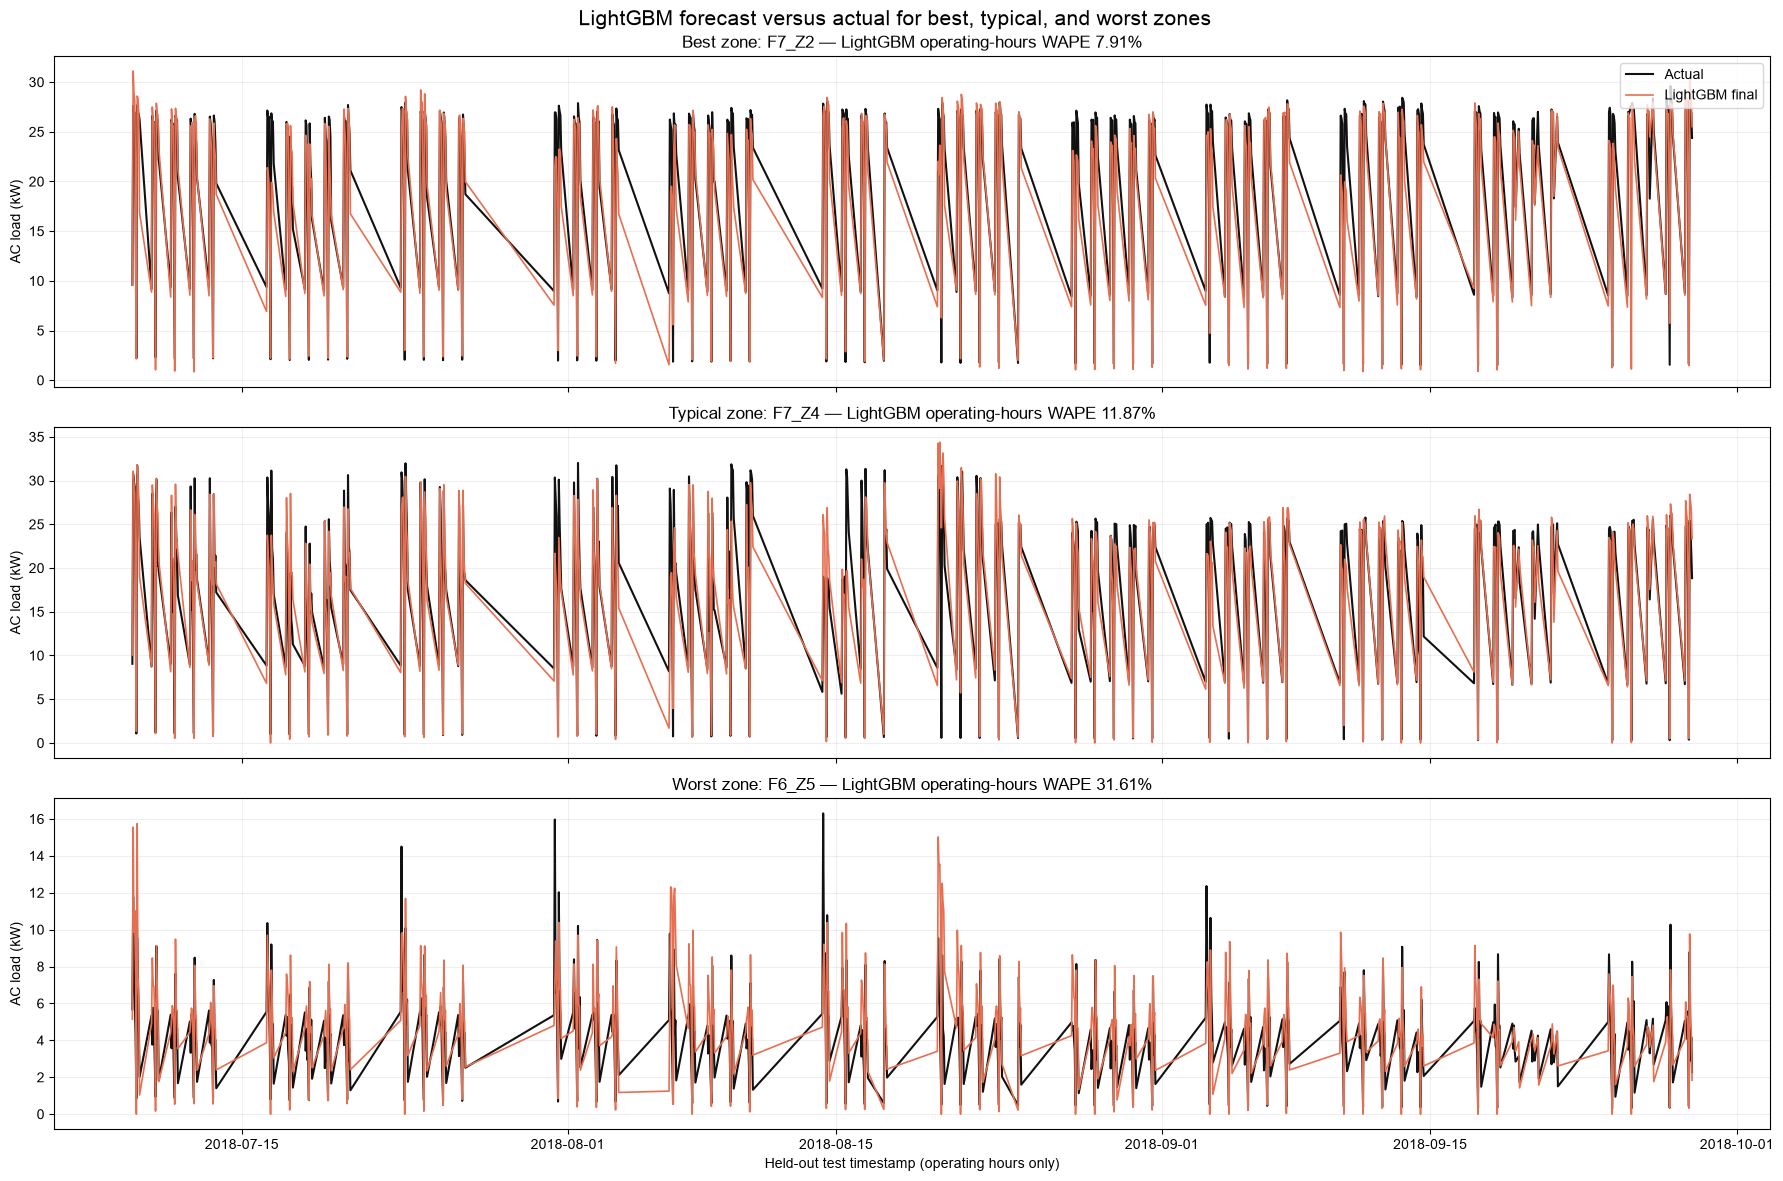

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(18, 12), sharex=True)
for ax, (label, zone) in zip(axes, selected_zones.items()):
    g = plot_df[plot_df.zone_id.eq(zone)].sort_values('timestamp')
    g = g[g.is_operating_hours.eq(1)]
    ax.plot(g.timestamp, g.ac_load_kw, label='Actual', color='#111111', linewidth=1.5)
    ax.plot(g.timestamp, g['LGBM final'], label='LightGBM final', color='#e76f51', linewidth=1.2)
    wape = zone_scores.loc[zone_scores.zone_id.eq(zone), 'WAPE%'].iloc[0]
    ax.set_title(f'{label} zone: {zone} — LightGBM operating-hours WAPE {wape:.2f}%')
    ax.set_ylabel('AC load (kW)')
    ax.grid(alpha=0.2)
axes[0].legend(loc='upper right')
axes[-1].set_xlabel('Held-out test timestamp (operating hours only)')
fig.suptitle('LightGBM forecast versus actual for best, typical, and worst zones', fontsize=15)
fig.tight_layout()
fig.savefig(OUT / 'lightgbm_forecast_vs_actual_best_typical_worst_zones.png', dpi=180, bbox_inches='tight')
plt.show()


## XGBoost selected M4 feature importance

This uses native XGBoost gain importance from the trained `correlation_reduced_M4` model. Gain measures the average improvement in the training objective contributed by splits on each feature; it is an explanation of what the model used, not a causal effect. Correlated variables can share or distort individual importance.


,feature,gain
0,ac_load_kw_last_week,7660.533
1,is_holiday,6307.129
2,ac_load_kw_yesterday,2267.659
3,weekday,1757.044
4,indoor_temp_c_last_week,1095.426
5,ac_load_kw_2_days_ago,542.481
6,hour,509.581
7,solar_radiation_hourly_wm2,491.869
8,zone_code,267.611
9,outdoor_temp_daily_avg_c,186.898


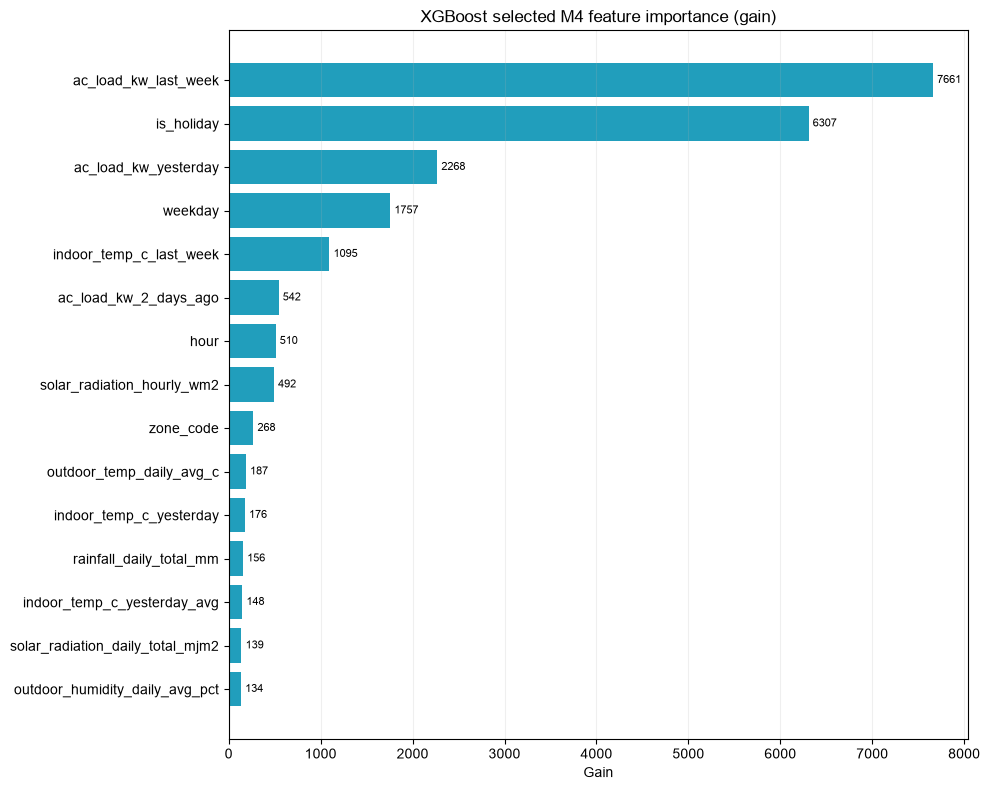

In [6]:
importance = pd.read_csv(ROOT / '4-XGBoost' / 'outputs' / 'final_models' / 'correlation_reduced_M4' / 'feature_importance.csv').sort_values('gain', ascending=True)
display(importance.sort_values('gain', ascending=False).head(15).round(3))
fig, ax = plt.subplots(figsize=(10, 8))
top = importance.tail(15)
bars = ax.barh(top['feature'], top['gain'], color='#219ebc')
ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=8)
ax.set_title('XGBoost selected M4 feature importance (gain)')
ax.set_xlabel('Gain')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'xgboost_selected_m4_feature_importance.png', dpi=180, bbox_inches='tight')
plt.show()


## LightGBM WAPE heatmap by floor and zone

Each square represents one zone. Color and annotation show LightGBM operating-hours WAPE on the held-out test period.


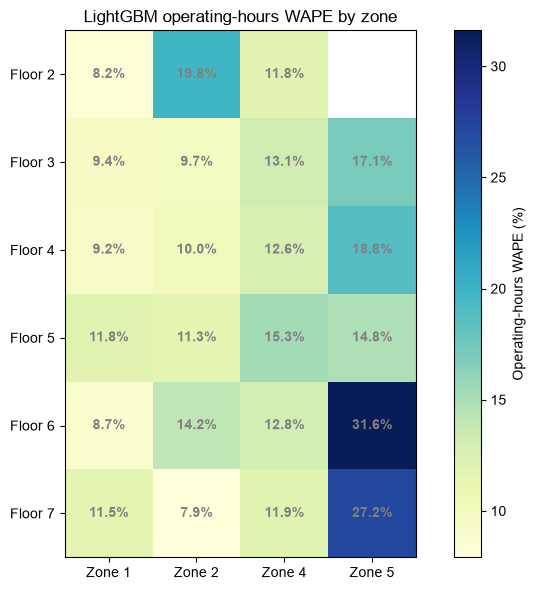

In [7]:
heat = zone_scores.pivot(index='floor', columns='zone_number', values='WAPE%').sort_index()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(heat, cmap="YlGnBu", vmin=heat.min().min(), vmax=heat.max().max())
ax.set_xticks(range(len(heat.columns)), [f'Zone {z}' for z in heat.columns])
ax.set_yticks(range(len(heat.index)), [f'Floor {f}' for f in heat.index])
for i, floor in enumerate(heat.index):
    for j, zone in enumerate(heat.columns):
        value = heat.loc[floor, zone]
        if pd.notna(value): ax.text(j, i, f'{value:.1f}%', ha='center', va='center', color='grey', fontweight='bold')
fig.colorbar(im, ax=ax, label='Operating-hours WAPE (%)')
ax.set_title('LightGBM operating-hours WAPE by zone')
fig.tight_layout()
fig.savefig(OUT / 'lightgbm_zone_wape_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
heat.to_csv(OUT / 'lightgbm_zone_wape_heatmap.csv')


## Aggregate LightGBM forecast versus actual

This line chart compares total actual and total LightGBM forecast AC load across all zones for each timestamp in the held-out test period.


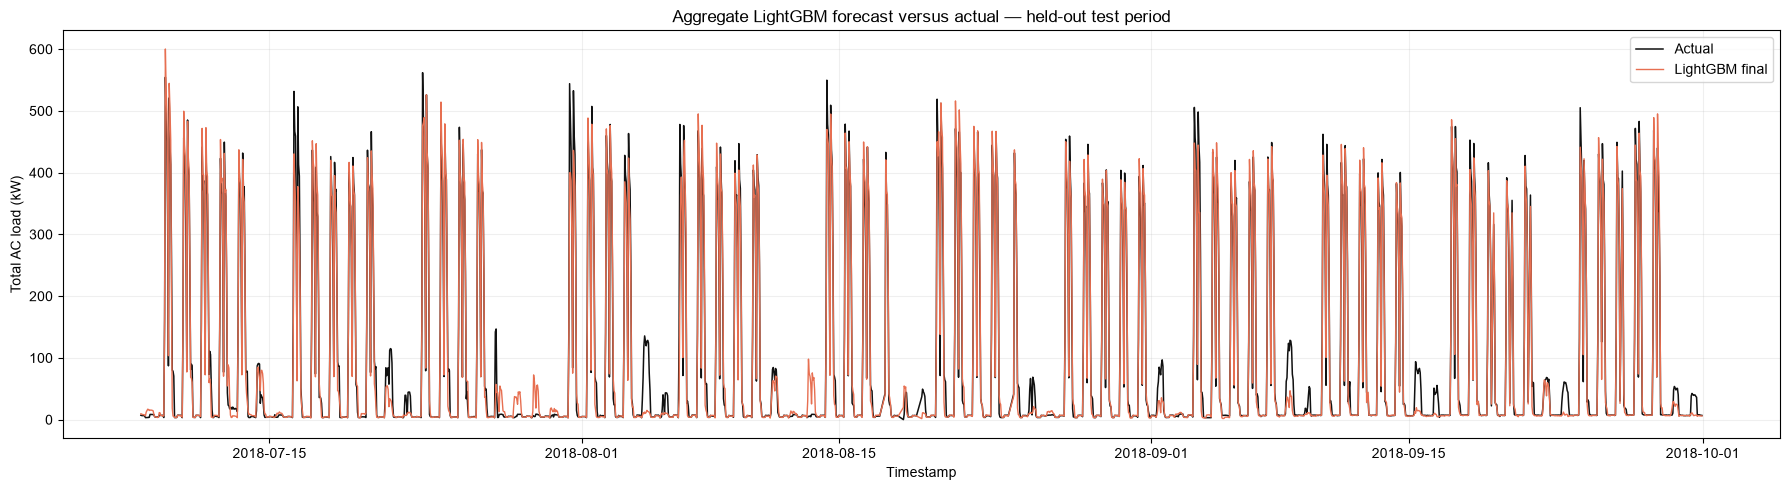

In [8]:
aggregate = plot_df.groupby('timestamp', as_index=False).agg(actual=('ac_load_kw','sum'), forecast=('LGBM final','sum'))
fig, ax = plt.subplots(figsize=(18, 5))
ax.plot(aggregate.timestamp, aggregate.actual, label='Actual', color='#111111', linewidth=1.1)
ax.plot(aggregate.timestamp, aggregate.forecast, label='LightGBM final', color='#e76f51', linewidth=1.0)
ax.set_title('Aggregate LightGBM forecast versus actual — held-out test period')
ax.set_xlabel('Timestamp')
ax.set_ylabel('Total AC load (kW)')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'lightgbm_aggregate_forecast_vs_actual.png', dpi=180, bbox_inches='tight')
plt.show()


## Per-zone accuracy heatmaps

All four heatmaps use scored operating-hours rows from the held-out test period. Difference metrics are calculated as `LightGBM - B1`; negative WAPE/MAE values mean LightGBM has lower error. CV(RMSE) and NMBE are LightGBM values.


In [9]:
rows = []
for zone, group in operating.groupby('zone_id', sort=True):
    actual = group['ac_load_kw'].to_numpy(float)
    lgbm_error = group['LGBM final'].to_numpy(float) - actual
    b1_error = group['B1 seasonal naive'].to_numpy(float) - actual
    mean_actual = actual.mean()
    actual_total = abs(actual).sum()
    rows.append({
        'zone_id': zone,
        'n': len(actual),
        'WAPE_LightGBM%': abs(lgbm_error).sum() / actual_total * 100,
        'WAPE_B1%': abs(b1_error).sum() / actual_total * 100,
        'WAPE_difference_LightGBM_minus_B1%': (abs(lgbm_error).sum() - abs(b1_error).sum()) / actual_total * 100,
        'MAE_LightGBM': abs(lgbm_error).mean(),
        'MAE_B1': abs(b1_error).mean(),
        'MAE_difference_LightGBM_minus_B1': abs(lgbm_error).mean() - abs(b1_error).mean(),
        'RMSE_LightGBM': (lgbm_error ** 2).mean() ** 0.5,
        'CV_RMSE_LightGBM%': ((lgbm_error ** 2).mean() ** 0.5) / mean_actual * 100 if mean_actual else float('nan'),
        'NMBE_LightGBM%': lgbm_error.mean() / mean_actual * 100 if mean_actual else float('nan'),
    })
zone_metrics = pd.DataFrame(rows)
zone_metrics['floor'] = zone_metrics['zone_id'].str.extract(r'F(\d+)_')[0].astype(int)
zone_metrics['zone_number'] = zone_metrics['zone_id'].str.extract(r'_Z(\d+)')[0].astype(int)
zone_metrics = zone_metrics.sort_values(['floor', 'zone_number']).reset_index(drop=True)
display(zone_metrics.round(3))
zone_metrics.to_csv(OUT / 'per_zone_lightgbm_b1_guideline_metrics.csv', index=False)


,zone_id,n,WAPE_LightGBM%,WAPE_B1%,WAPE_difference_LightGBM_minus_B1%,MAE_LightGBM,MAE_B1,MAE_difference_LightGBM_minus_B1,RMSE_LightGBM,CV_RMSE_LightGBM%,NMBE_LightGBM%,floor,zone_number
0,F2_Z1,552,8.156,15.282,-7.125,2.107,3.949,-1.841,3.123,12.085,-0.695,2,1
1,F2_Z2,546,19.791,20.474,-0.683,4.103,4.244,-0.142,5.700,27.500,13.889,2,2
2,F2_Z4,548,11.800,8.213,3.587,1.090,0.759,0.331,1.483,16.055,-10.236,2,4
3,F3_Z1,546,9.362,11.731,-2.369,1.605,2.011,-0.406,2.736,15.961,-4.487,3,1
4,F3_Z2,548,9.666,15.427,-5.761,1.275,2.034,-0.760,1.891,14.338,-1.925,3,2
5,F3_Z4,552,13.114,20.078,-6.964,1.619,2.478,-0.860,2.623,21.251,3.531,3,4
6,F3_Z5,548,17.093,21.018,-3.925,1.223,1.504,-0.281,1.852,25.868,-9.113,3,5
7,F4_Z1,546,9.219,12.952,-3.734,1.448,2.034,-0.586,2.406,15.320,-1.715,4,1
8,F4_Z2,548,10.045,15.613,-5.568,1.107,1.720,-0.614,1.595,14.471,3.289,4,2
9,F4_Z4,548,12.581,17.380,-4.799,1.768,2.443,-0.675,2.745,19.528,2.210,4,4


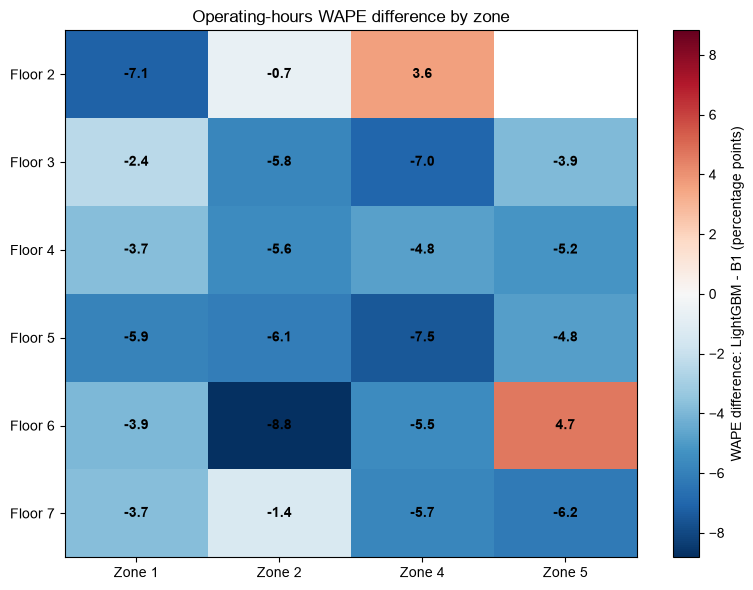

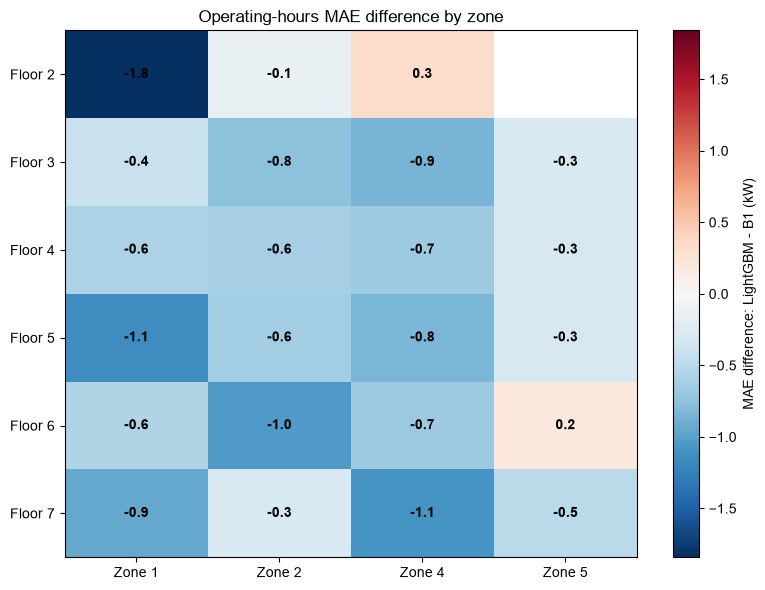

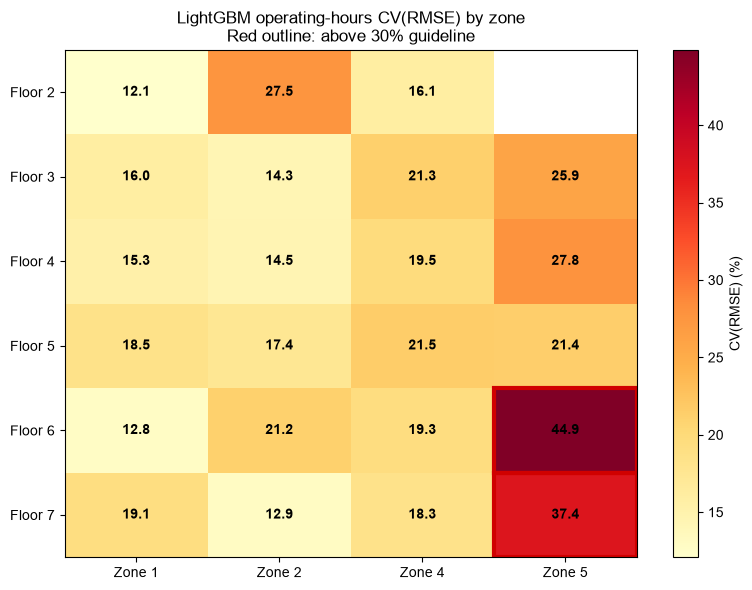

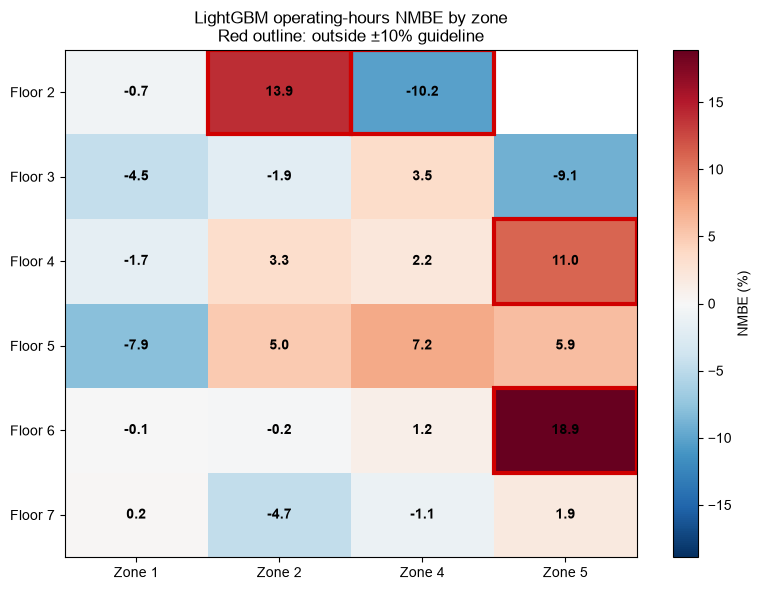

In [10]:
def draw_zone_heatmap(frame, value_column, title, colorbar_label, filename, csv_filename,
                     cmap='RdBu_r', center=0, threshold=None, threshold_mode=None,
                     value_format='{:.1f}'):
    heat = frame.pivot(index='floor', columns='zone_number', values=value_column).sort_index()
    finite = heat.to_numpy(float)
    finite = finite[pd.notna(finite)]
    if center is not None:
        max_abs = max(abs(finite.min() - center), abs(finite.max() - center), 1e-9)
        norm = plt.Normalize(center - max_abs, center + max_abs)
    else:
        norm = plt.Normalize(finite.min(), finite.max())
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(heat, cmap=cmap, norm=norm, aspect='auto')
    ax.set_xticks(range(len(heat.columns)), [f'Zone {z}' for z in heat.columns])
    ax.set_yticks(range(len(heat.index)), [f'Floor {f}' for f in heat.index])
    for i, floor in enumerate(heat.index):
        for j, zone in enumerate(heat.columns):
            value = heat.loc[floor, zone]
            if pd.notna(value):
                ax.text(j, i, value_format.format(value), ha='center', va='center', color='black', fontweight='bold')
                failed = False
                if threshold is not None and threshold_mode == 'above':
                    failed = value > threshold
                elif threshold is not None and threshold_mode == 'outside':
                    failed = abs(value) > threshold
                if failed:
                    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor='#d00000', linewidth=3))
    if threshold is not None:
        if threshold_mode == 'above':
            subtitle = f'Red outline: above {threshold:g}% guideline'
        else:
            subtitle = f'Red outline: outside ±{threshold:g}% guideline'
        ax.set_title(f'{title}\n{subtitle}')
    else:
        ax.set_title(title)
    fig.colorbar(im, ax=ax, label=colorbar_label)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=180, bbox_inches='tight')
    plt.show()
    heat.to_csv(OUT / csv_filename)
    return heat

wape_heat = draw_zone_heatmap(
    zone_metrics, 'WAPE_difference_LightGBM_minus_B1%',
    'Operating-hours WAPE difference by zone', 'WAPE difference: LightGBM - B1 (percentage points)',
    'lightgbm_vs_b1_zone_wape_difference_heatmap.png', 'lightgbm_vs_b1_zone_wape_difference_heatmap.csv')
mae_heat = draw_zone_heatmap(
    zone_metrics, 'MAE_difference_LightGBM_minus_B1',
    'Operating-hours MAE difference by zone', 'MAE difference: LightGBM - B1 (kW)',
    'lightgbm_vs_b1_zone_mae_difference_heatmap.png', 'lightgbm_vs_b1_zone_mae_difference_heatmap.csv')
cv_heat = draw_zone_heatmap(
    zone_metrics, 'CV_RMSE_LightGBM%',
    'LightGBM operating-hours CV(RMSE) by zone', 'CV(RMSE) (%)',
    'lightgbm_zone_cv_rmse_heatmap.png', 'lightgbm_zone_cv_rmse_heatmap.csv',
    cmap='YlOrRd', center=None, threshold=30, threshold_mode='above')
nmbe_heat = draw_zone_heatmap(
    zone_metrics, 'NMBE_LightGBM%',
    'LightGBM operating-hours NMBE by zone', 'NMBE (%)',
    'lightgbm_zone_nmbe_heatmap.png', 'lightgbm_zone_nmbe_heatmap.csv',
    cmap='RdBu_r', center=0, threshold=10, threshold_mode='outside')


## Weather-noise validation for selected LightGBM

This stress test uses the saved selected `LGBM final` model trained on all 2019 data. It evaluates the same scored held-out 2018 rows after perturbing the weather inputs to represent imperfect day-ahead forecasts. Temperature noise is sampled with a standard deviation of 1.5°C and 10% of daily rainfall signals are flipped. The model is not retrained.


In [11]:
import sys
import numpy as np
sys.path.insert(0, str(ROOT / '3-LightGBM'))
from ac_forecaster import ACLoadForecaster

MODEL_DIR = ROOT / '3-LightGBM' / 'outputs' / 'ac_forecaster'
SCREENED_DATA = ROOT / 'Feature Selection' / 'Output' / 'question_b_model_data_screened.parquet'
weather_model = ACLoadForecaster.load(MODEL_DIR)
print(weather_model)
print('Weather features used:', [f for f in weather_model.features if 'outdoor' in f or 'rainfall' in f or 'solar' in f])


ACLoadForecaster(14 features, 23 zones, 4236 trees)
Weather features used: ['outdoor_temp_daily_avg_c', 'outdoor_humidity_hourly_pct', 'rainfall_daily_total_mm', 'solar_radiation_hourly_wm2']


In [12]:
weather_predictions = lgbm_pred[lgbm_pred['scored'].eq(1)].copy()
weather_predictions['timestamp'] = pd.to_datetime(weather_predictions['timestamp'])
model_data = pd.read_parquet(SCREENED_DATA)
model_data['timestamp'] = pd.to_datetime(model_data['timestamp'])
weather_inputs = model_data.merge(
    weather_predictions[['zone_id', 'timestamp', 'scored', 'is_operating_hours', 'ac_load_kw']],
    on=['zone_id', 'timestamp'], how='inner', suffixes=('', '_prediction')
)
weather_inputs = weather_inputs[weather_inputs['scored'].eq(1)].copy()

# Apply a deterministic, documented forecast-error scenario.
noisy_inputs = weather_inputs.copy()
rng = np.random.default_rng(2026)
noisy_inputs['outdoor_temp_daily_avg_c'] = noisy_inputs['outdoor_temp_daily_avg_c'] + rng.normal(0, 1.5, len(noisy_inputs))
rainy = noisy_inputs['rainfall_daily_total_mm'].fillna(0).gt(0)
rain_flip = rng.random(len(noisy_inputs)) < 0.10
noisy_inputs.loc[rain_flip & rainy, 'rainfall_daily_total_mm'] = 0.0
noisy_inputs.loc[rain_flip & ~rainy, 'rainfall_daily_total_mm'] = 0.1

weather_inputs['LightGBM clean'] = weather_model.predict(weather_inputs)
weather_inputs['LightGBM noisy weather'] = weather_model.predict(noisy_inputs)
weather_inputs['weather_prediction_change_kw'] = weather_inputs['LightGBM noisy weather'] - weather_inputs['LightGBM clean']
weather_inputs['weather_noise_rain_flipped'] = rain_flip
print('Scored rows used:', len(weather_inputs))
print('Operating rows used:', int(weather_inputs['is_operating_hours'].eq(1).sum()))
print('Rainfall signals flipped:', int(rain_flip.sum()))


Scored rows used: 46064
Operating rows used: 12602
Rainfall signals flipped: 4630


In [13]:
def score_weather_scenario(frame, prediction_column):
    operating = frame[frame['is_operating_hours'].eq(1)].copy()
    actual = operating['ac_load_kw'].to_numpy(float)
    predicted = operating[prediction_column].to_numpy(float)
    error = predicted - actual
    mean_actual = actual.mean()
    rmse = (error ** 2).mean() ** 0.5
    return {
        'n_operating_hours': len(actual),
        'MAE': abs(error).mean(),
        'RMSE': rmse,
        'CV(RMSE)%': rmse / mean_actual * 100,
        'NMBE%': error.mean() / mean_actual * 100,
        'WAPE%': abs(error).sum() / abs(actual).sum() * 100,
    }

weather_scores = pd.DataFrame([
    {'scenario': 'Clean weather', **score_weather_scenario(weather_inputs, 'LightGBM clean')},
    {'scenario': 'Noisy weather', **score_weather_scenario(weather_inputs, 'LightGBM noisy weather')},
])
for metric in ['MAE', 'RMSE', 'CV(RMSE)%', 'NMBE%', 'WAPE%']:
    clean = weather_scores.loc[weather_scores['scenario'].eq('Clean weather'), metric].iloc[0]
    noisy = weather_scores.loc[weather_scores['scenario'].eq('Noisy weather'), metric].iloc[0]
    weather_scores.loc[weather_scores['scenario'].eq('Noisy weather'), f'{metric} change'] = noisy - clean
weather_scores = weather_scores.round(3)
display(weather_scores)
weather_scores.to_csv(OUT / 'lightgbm_weather_noise_validation.csv', index=False)
weather_inputs[['zone_id','timestamp','ac_load_kw','is_operating_hours','LightGBM clean','LightGBM noisy weather','weather_prediction_change_kw','weather_noise_rain_flipped']].to_csv(OUT / 'lightgbm_weather_noise_predictions.csv', index=False)


,scenario,n_operating_hours,MAE,RMSE,CV(RMSE)%,NMBE%,WAPE%,MAE change,RMSE change,CV(RMSE)% change,NMBE% change,WAPE% change
0,Clean weather,12602,1.708,2.779,20.326,0.514,12.489,NaN,NaN,NaN,NaN,NaN
1,Noisy weather,12602,1.818,2.900,21.207,-0.323,13.295,0.11,0.12,0.881,-0.837,0.806


In [14]:
zone_noise_rows = []
for zone, group in weather_inputs.groupby('zone_id', sort=True):
    clean = score_weather_scenario(group, 'LightGBM clean')
    noisy = score_weather_scenario(group, 'LightGBM noisy weather')
    zone_noise_rows.append({
        'zone_id': zone,
        'clean_WAPE%': clean['WAPE%'],
        'noisy_WAPE%': noisy['WAPE%'],
        'WAPE_change_pp': noisy['WAPE%'] - clean['WAPE%'],
        'clean_MAE': clean['MAE'],
        'noisy_MAE': noisy['MAE'],
        'MAE_change_kw': noisy['MAE'] - clean['MAE'],
    })
zone_noise = pd.DataFrame(zone_noise_rows).sort_values('WAPE_change_pp', ascending=False)
display(zone_noise.round(3))
zone_noise.to_csv(OUT / 'lightgbm_weather_noise_by_zone.csv', index=False)


,zone_id,clean_WAPE%,noisy_WAPE%,WAPE_change_pp,clean_MAE,noisy_MAE,MAE_change_kw
20,F7_Z2,7.913,9.374,1.461,1.658,1.964,0.306
3,F3_Z1,9.362,10.670,1.309,1.605,1.829,0.224
9,F4_Z4,12.581,13.856,1.275,1.768,1.948,0.179
11,F5_Z1,11.833,13.047,1.214,2.304,2.541,0.236
6,F3_Z5,17.093,18.269,1.175,1.223,1.308,0.084
15,F6_Z1,8.663,9.681,1.018,1.217,1.360,0.143
16,F6_Z2,14.205,15.178,0.974,1.671,1.786,0.115
12,F5_Z2,11.346,12.290,0.943,1.203,1.303,0.100
0,F2_Z1,8.156,9.048,0.891,2.107,2.338,0.230
7,F4_Z1,9.219,10.100,0.881,1.448,1.586,0.138


## Weather-noise conclusion

Under this deterministic stress scenario, the selected LightGBM model remains reasonably robust but loses some accuracy when weather inputs are imperfect. Operating-hours WAPE increases from **12.49%** with clean inputs to **13.30%** with noisy weather (**+0.81 percentage points**). MAE increases from **1.708 kW** to **1.818 kW**, and CV(RMSE) increases from **20.33%** to **21.21%**. The noisy-weather result remains below the B1 operating-hours WAPE of **16.92%**, so LightGBM still outperforms B1 under this tested error scenario.

The degradation is not uniform across zones. The largest WAPE increases are in `F7_Z2` (+1.46 percentage points), `F3_Z1` (+1.31 pp), and `F4_Z4` (+1.28 pp). `F6_Z5` remains the weakest zone, but its WAPE changes only slightly (+0.49 pp) because its clean-weather error is already high. This is a robustness stress test, not a calibrated historical forecast-error evaluation; actual weather forecast errors would provide a stronger validation scenario.
